# Step 7 — Pipeline: momentum tilt plus regime-scaled exposure, assembled month by month

The full monthly decision chain. Base weights from Step 5 receive a 12-1 month momentum tilt, capped at ±20%
of each weight and applied strictly after optimization (rule 4), then total exposure is scaled by the regime
label — 100% / 80% / 50% for CALM / NORMAL / STRESS in this standard map, with the freed capital parked in SHY.
Eight track-variants are assembled (Risk Parity on raw, Ledoit-Wolf and EWMA covariance, with and without
each layer, plus minimum variance), so Step 8 can attribute performance layer by layer. One detail that
matters for reading the backtest: the detector's first label is 2013-01, so before that every track runs at
the fixed NORMAL exposure.

<details>
<summary><b>Specification — the prompt for this step, verbatim (click to expand)</b></summary>

# Step 7 — Specification

> Full prompt for this step, reproduced verbatim (capstone_project_rules.md code-style rule:
> each notebook opens with its own spec so it is self-contained).

STEP 7 — Momentum tilt + full monthly pipeline assembly

Read capstone_project_rules.md first. Implement ONLY this step, in notebooks/07_pipeline.ipynb.
First cell: this entire prompt in markdown, titled "# Step 7 — Specification".

## PRE-STEP: addition to step 5 (run first, ~10 lines)
Compute RP weights using the RAW sample covariance from step 3
(outputs/cov_sample.parquet) — track name "RP-RAW". Same ERC method and
schedule as step 5. Append to outputs/weights_base.parquet.
This completes the ladder raw -> LW -> EWMA so step 8 can measure the
contribution of shrinkage itself, not just LW-vs-EWMA.

## Goal
Assemble the complete monthly decision chain for the first time:
  base weights (step 5)  ->  momentum tilt  ->  regime exposure scaling
  ->  FINAL weights (6 assets + SHY residual)
Point-in-time throughout. Still NO performance evaluation (step 8).

## Momentum tilt
For each month-end T and each of the 6 optimizable assets:
1. momentum signal = cumulative return over months T-12..T-1 (12-1:
   exclude the most recent month). Use adjusted monthly closes derived
   from prices_daily.parquet.
2. Cross-sectional rank of the 6 signals; map rank to tilt linearly:
   best = +0.20, worst = -0.20, evenly spaced.
3. w_tilted_i = w_base_i * (1 + tilt_i); renormalize to sum 1.
4. If an asset lacks 13 months of history at T, tilt_i = 0 for it.

## Regime exposure scaling
Using official_v2 labels from step 6:
  CALM -> exposure 1.00 ; NORMAL -> 0.80 ; STRESS -> 0.50
final_i = w_tilted_i * exposure ; SHY_weight = 1 - exposure.
For month-ends BEFORE the regime series starts (~2012), use exposure 0.80
(NORMAL) as conservative default and flag those months in the output.

## Tracks to assemble
- RP-LW and RP-EWMA: three variants each — base only / base+tilt /
  base+tilt+regime (full chain).
- MinVar-LW: full chain only (comparison).
- RP-RAW: full chain only (shrinkage baseline).
Total: 8 weight tracks.

## Outputs
outputs/weights_final.parquet: date, track, variant, asset (incl SHY),
weight.

## Diagnostics
1. Stacked area of the FULL chain for RP-LW (6 assets + SHY). SHY should
   appear as a visible band exactly in the red/gray periods of step 6.
2. One example month (2020-03-31, RP-LW): print the chain step by step —
   base -> tilted -> scaled+SHY. Hand-checkable table.
3. Tilt behavior: time series of the tilt applied to XLE and GLD.
   Sanity: XLE tilt strongly negative through 2015-16 and 2020, positive
   2021-22; GLD positive 2011, 2019-20, 2024-25.
4. Turnover: mean monthly one-way turnover of base vs base+tilt vs full
   chain, per track. Quantify what each layer adds. Flag if any full
   chain exceeds 20% one-way monthly.
5. Average exposure over time (full chain): one line per track; long-run
   mean should sit ~0.90-0.95 given regime frequencies (70/22/8).

## Sanity notes
- Point-in-time: tilt at T uses returns through month T-1 only; regime
  label at T is official_v2 AT T (no peeking).
- Weights (6 assets + SHY) must sum to 1.000 every month — assert it.
- No costs, no strategy returns yet — that's step 8.

</details>

## 0 — Setup: load base weights, regime, monthly prices

Inputs: Step 5 base weights (now including the **RP-RAW** track from the pre-step,
so the raw → LW → EWMA ladder is complete), Step 6 regime labels (`official_v2`),
and monthly adjusted closes derived from Step 1's `prices_daily.parquet` (resampled
to month-end) for the momentum signal.

Tracks assembled: **RP-LW** and **RP-EWMA** get all three variants
(base / base+tilt / full chain); **MinVar-LW** and **RP-RAW** get the full chain
only — 8 track-variants in total.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

OPT6 = ["SPY", "VEA", "XLE", "XLU", "IEF", "GLD"]
ALL7 = OPT6 + ["SHY"]
EXPO = {"CALM": 1.00, "NORMAL": 0.80, "STRESS": 0.50}
COLORS = {"SPY": "#1f77b4", "VEA": "#ff7f0e", "XLE": "#8c564b", "XLU": "#9467bd",
          "IEF": "#2ca02c", "GLD": "#d4af37", "SHY": "#444444"}
TRACKS = {"RP-LW": ("RP", "LW"), "RP-EWMA": ("RP", "EWMA"),
          "MinVar-LW": ("MinVar", "LW"), "RP-RAW": ("RP", "RAW")}
FULL_ONLY = {"MinVar-LW", "RP-RAW"}       # emit only the full chain for these two
VARIANTS = ["base", "base+tilt", "base+tilt+regime"]

CWD = Path.cwd()
ROOT = CWD.parent if CWD.name == "notebooks" else CWD
DATA_DIR, OUT_DIR = ROOT / "data", ROOT / "outputs"

wb = pd.read_parquet(OUT_DIR / "weights_base.parquet")
reg = pd.read_parquet(OUT_DIR / "regime_v1.parquet").set_index("date")

def base_track(method, covn):
    d = wb[(wb.method == method) & (wb.cov_input == covn)]
    return d.pivot(index="date", columns="asset", values="weight")[OPT6]

base_w = {name: base_track(m, c) for name, (m, c) in TRACKS.items()}
schedule = base_w["RP-LW"].index                       # 192 month-ends from Step 5

# monthly adjusted closes -> 12-1 momentum (exclude most recent month)
monthly = pd.read_parquet(DATA_DIR / "prices_daily.parquet")[OPT6].resample("ME").last()
mom = monthly.shift(1) / monthly.shift(13) - 1         # P_{T-1}/P_{T-13}-1 = months T-12..T-1

regime_start = reg.index.min()
n_pre = int((schedule < regime_start).sum())
print(f"schedule: {len(schedule)} months {schedule.min().date()} -> {schedule.max().date()}")
print(f"regime series starts {regime_start.date()}; {n_pre} pre-regime months use NORMAL(0.80) default")
print(f"momentum NaN at schedule dates: {int(mom.loc[schedule].isna().sum().sum())} (expect 0)")

schedule: 193 months 2010-07-31 -> 2026-07-31
regime series starts 2013-01-31; 30 pre-regime months use NORMAL(0.80) default
momentum NaN at schedule dates: 0 (expect 0)


## 1 — Momentum tilt (per month-end)

12-1 momentum ranked cross-sectionally, mapped linearly to a ±0.20 tilt
(best → +0.20, worst → −0.20). An asset lacking 13 months of history gets tilt 0
and is excluded from the ranking. The tilt depends only on the date (asset
momentum), so it is shared across all tracks.

In [2]:
def momentum_tilt(T):
    m = mom.loc[T]
    valid = m.dropna()                                  # assets with >= 13 months history
    tilt = pd.Series(0.0, index=OPT6)
    if len(valid) >= 2:
        rank = valid.rank(method="average")             # 1..n ascending (worst..best)
        tilt.loc[valid.index] = -0.20 + 0.40 * (rank - 1) / (len(valid) - 1)
    return tilt

tilt_df = pd.DataFrame({T: momentum_tilt(T) for T in schedule}).T[OPT6]
print("tilt range per asset (should be within [-0.20, +0.20]):")
print(tilt_df.agg(["min", "max"]).round(3).to_string())

tilt range per asset (should be within [-0.20, +0.20]):


     SPY  VEA  XLE  XLU  IEF  GLD
min -0.2 -0.2 -0.2 -0.2 -0.2 -0.2
max  0.2  0.2  0.2  0.2  0.2  0.2


## 2 — Assemble the chain (base → tilt → regime) for the 3 tracks

For each track and month-end: `base` (6 assets), `base+tilt` (renormalized), and
`base+tilt+regime` (scaled by exposure, with `SHY = 1 − exposure`). Pre-regime
months use the NORMAL(0.80) default and are flagged. Every variant is padded to
7 assets (SHY = 0 where no regime scaling) and asserted to sum to 1.

In [3]:
def exposure_at(T):
    if T in reg.index:
        return EXPO[reg.loc[T, "official_v2"]], False
    return 0.80, True                                   # pre-regime NORMAL default, flagged

rows = []
for T in schedule:
    tilt = tilt_df.loc[T]
    exp, defaulted = exposure_at(T)
    for name, Wb in base_w.items():
        wbse = Wb.loc[T]
        wt = wbse * (1 + tilt); wt = wt / wt.sum()
        variant_w = {"base+tilt+regime": (wt * exp, 1 - exp, defaulted)}
        if name not in FULL_ONLY:                       # RP-LW / RP-EWMA also keep base & base+tilt
            variant_w["base"] = (wbse, 0.0, False)
            variant_w["base+tilt"] = (wt, 0.0, False)
        for vname, (w6, shy, flag) in variant_w.items():
            for a in OPT6:
                rows.append((T, name, vname, a, float(w6[a]), flag))
            rows.append((T, name, vname, "SHY", float(shy), flag))

weights_final = pd.DataFrame(rows, columns=["date", "track", "variant", "asset", "weight", "regime_defaulted"])

# assert every (date,track,variant) sums to 1
sums = weights_final.groupby(["date", "track", "variant"])["weight"].sum()
assert np.allclose(sums.values, 1.0, atol=1e-9), f"weights do not sum to 1 (min={sums.min()}, max={sums.max()})"
n_tv = weights_final[["track", "variant"]].drop_duplicates().shape[0]
print(f"built {weights_final.shape[0]} rows; all (date,track,variant) sum to 1.000 "
      f"[{n_tv} track-variants x {len(schedule)} months x 7 assets]")
print("track-variants:", sorted(weights_final.groupby('track')['variant'].nunique().to_dict().items()))

built 10808 rows; all (date,track,variant) sum to 1.000 [8 track-variants x 193 months x 7 assets]
track-variants: [('MinVar-LW', 1), ('RP-EWMA', 3), ('RP-LW', 3), ('RP-RAW', 1)]


## 3 — Save `outputs/weights_final.parquet`

Long format: `date, track, variant, asset (incl SHY), weight`, plus a
`regime_defaulted` flag for pre-regime months.

In [4]:
p = OUT_DIR / "weights_final.parquet"
weights_final.to_parquet(p, index=False)
print(f"saved {p.name}  rows={len(weights_final)}  {p.stat().st_size/1024:.1f} KB")
print(f"flagged (pre-regime default) rows: {int(weights_final.regime_defaulted.sum())}")

saved weights_final.parquet  rows=10808  90.0 KB
flagged (pre-regime default) rows: 840


# Diagnostics

### D1 — Full chain for RP-LW (6 assets + SHY)

SHY should appear as a visible band precisely in the NORMAL/STRESS periods of
Step 6 (the freed capital when exposure < 1).

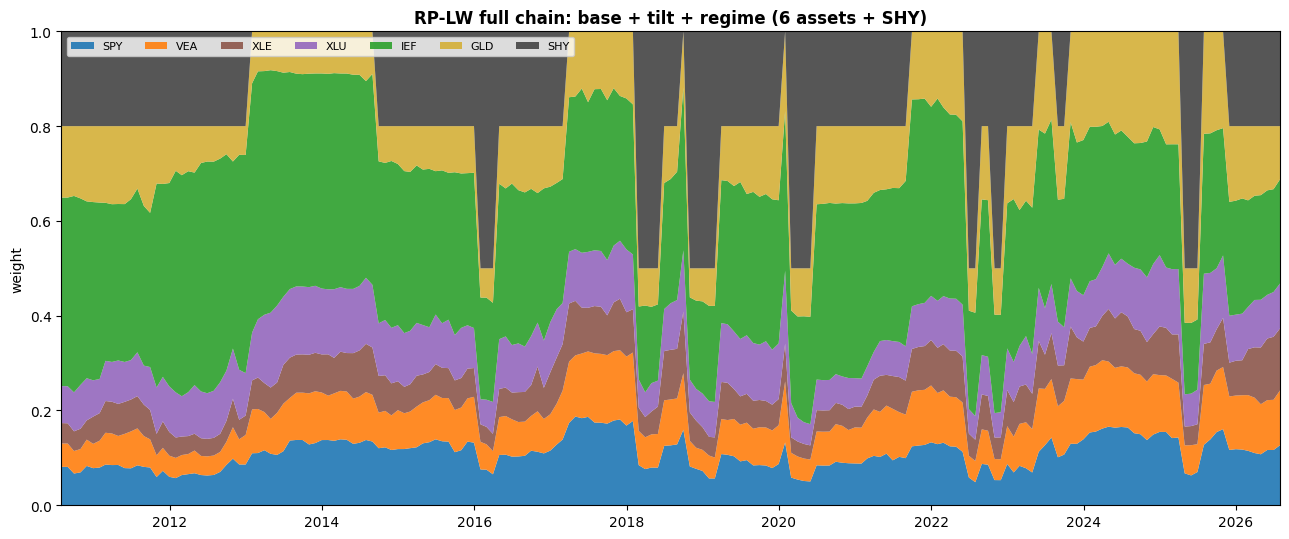

SHY weight: mean=0.166  max=0.500 (2016-01-31)


In [5]:
full_rplw = (weights_final[(weights_final.track == "RP-LW") &
             (weights_final.variant == "base+tilt+regime")]
             .pivot(index="date", columns="asset", values="weight")[ALL7])

fig, ax = plt.subplots(figsize=(13, 5.5))
ax.stackplot(full_rplw.index, [full_rplw[a].values for a in ALL7],
             labels=ALL7, colors=[COLORS[a] for a in ALL7], alpha=0.9)
ax.set_title("RP-LW full chain: base + tilt + regime (6 assets + SHY)", fontweight="bold")
ax.set_ylabel("weight"); ax.set_xlabel(""); ax.set_ylim(0, 1); ax.margins(x=0)
ax.legend(loc="upper left", ncol=7, fontsize=8)
plt.tight_layout(); plt.show()
print(f"SHY weight: mean={full_rplw['SHY'].mean():.3f}  max={full_rplw['SHY'].max():.3f} "
      f"({full_rplw['SHY'].idxmax().date()})")

### D2 — Worked example: 2020-03-31, RP-LW (hand-checkable)

base → (×(1+tilt), renormalize) → tilted → (×exposure, +SHY) → final.

In [6]:
T = pd.Timestamp("2020-03-31")
wbse = base_w["RP-LW"].loc[T]
tilt = tilt_df.loc[T]
wt = wbse * (1 + tilt); wt = wt / wt.sum()
exp, _ = exposure_at(T)
final6 = wt * exp

tbl = pd.DataFrame({"momentum_12_1": mom.loc[T], "tilt": tilt,
                    "base": wbse, "tilted": wt, f"final(x{exp:.2f})": final6}).round(4)
print(f"regime official_v2 = {reg.loc[T, 'official_v2']}  ->  exposure = {exp:.2f}\n")
print(tbl.to_string())
print(f"\nSHY = 1 - exposure = {1 - exp:.4f}")
print(f"check: sum(final6)+SHY = {final6.sum() + (1 - exp):.6f}")
print(f"check: tilted renormalized sum = {wt.sum():.6f}")

regime official_v2 = STRESS  ->  exposure = 0.50

     momentum_12_1  tilt    base  tilted  final(x0.50)
SPY         0.0832 -0.04  0.1189  0.1084        0.0542
VEA        -0.0011 -0.12  0.1166  0.0975        0.0488
XLE        -0.2595 -0.20  0.0832  0.0633        0.0316
XLU         0.1248  0.04  0.1013  0.1001        0.0501
IEF         0.1494  0.12  0.4016  0.4274        0.2137
GLD         0.1967  0.20  0.1783  0.2033        0.1017

SHY = 1 - exposure = 0.5000
check: sum(final6)+SHY = 1.000000
check: tilted renormalized sum = 1.000000


### D3 — Momentum tilt applied to XLE and GLD

The two streakiest assets. Sanity: XLE tilt strongly negative through 2015–16 and
2020 (oil busts), positive 2021–22 (energy rally); GLD positive 2011, 2019–20,
2024–25.

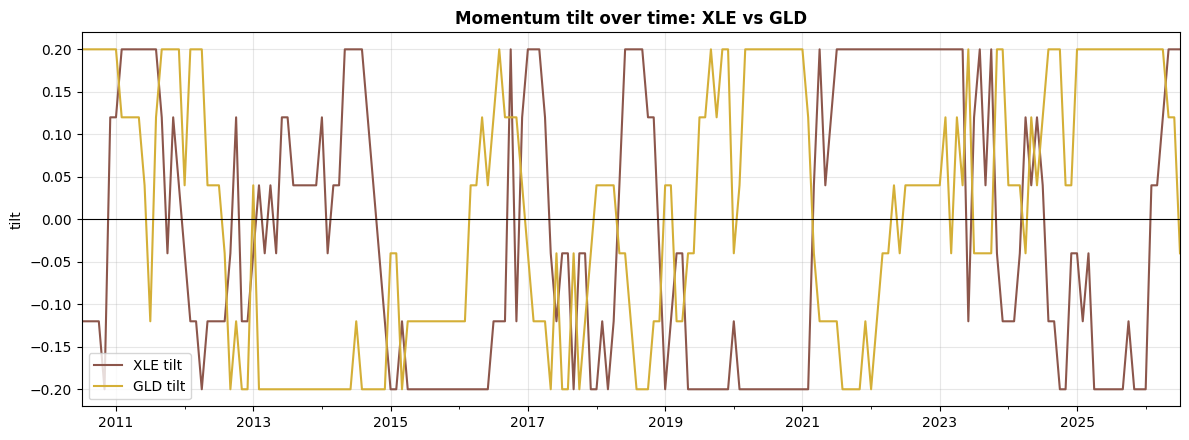

XLE: 2015-16 avg=-0.153  2020 avg=-0.193  2021-22 avg=+0.150  2024-25 avg=-0.107
GLD: 2015-16 avg=-0.027  2020 avg=+0.167  2021-22 avg=-0.053  2024-25 avg=+0.143


In [7]:
fig, ax = plt.subplots(figsize=(12, 4.5))
tilt_df["XLE"].plot(ax=ax, color=COLORS["XLE"], linewidth=1.5, label="XLE tilt")
tilt_df["GLD"].plot(ax=ax, color=COLORS["GLD"], linewidth=1.5, label="GLD tilt")
ax.axhline(0, color="black", linewidth=0.8)
ax.set_ylim(-0.22, 0.22)
ax.set_title("Momentum tilt over time: XLE vs GLD", fontweight="bold")
ax.set_ylabel("tilt"); ax.set_xlabel(""); ax.legend(); ax.grid(True, alpha=0.3)
plt.tight_layout(); plt.show()
for a in ["XLE", "GLD"]:
    s = tilt_df[a]
    print(f"{a}: 2015-16 avg={s['2015':'2016'].mean():+.3f}  2020 avg={s['2020'].mean():+.3f}  "
          f"2021-22 avg={s['2021':'2022'].mean():+.3f}  2024-25 avg={s['2024':'2025'].mean():+.3f}")

### D4 — Turnover: base vs base+tilt vs full chain

One-way monthly turnover = ½·Σ|wₜ − wₜ₋₁|. The tilt and regime layers add turnover;
we quantify it and flag any full-chain track above 20% one-way monthly.

In [8]:
def one_way(track, variant):
    d = weights_final[(weights_final.track == track) & (weights_final.variant == variant)]
    if d.empty:                                          # variant not emitted for this track
        return np.nan
    W = d.pivot(index="date", columns="asset", values="weight")[ALL7]
    return (W.diff().abs().sum(axis=1).iloc[1:] / 2).mean()

turn = pd.DataFrame({v: {t: one_way(t, v) for t in TRACKS} for v in VARIANTS})
print("mean one-way monthly turnover (%)  [NaN = variant not produced for that track]:")
print((turn * 100).round(2).to_string())
flagged = turn["base+tilt+regime"][turn["base+tilt+regime"] > 0.20]
print("\n" + ("FLAG full-chain > 20%: " + ", ".join(flagged.index) if len(flagged)
              else "no full-chain track exceeds 20% one-way monthly turnover."))

mean one-way monthly turnover (%)  [NaN = variant not produced for that track]:
           base  base+tilt  base+tilt+regime
RP-LW      0.71       2.59              5.71
RP-EWMA    1.90       3.35              6.19
MinVar-LW   NaN        NaN              6.26
RP-RAW      NaN        NaN              5.65

no full-chain track exceeds 20% one-way monthly turnover.


### D5 — Average exposure over time (full chain)

Exposure depends only on the regime, so it is identical across tracks (one line).
Long-run mean sits near 0.83 (printed below): CALM 41% / NORMAL 45% / STRESS 14% of regime months under the
standard 100/80/50 map, plus the 0.80 default before the detector starts in 2013.

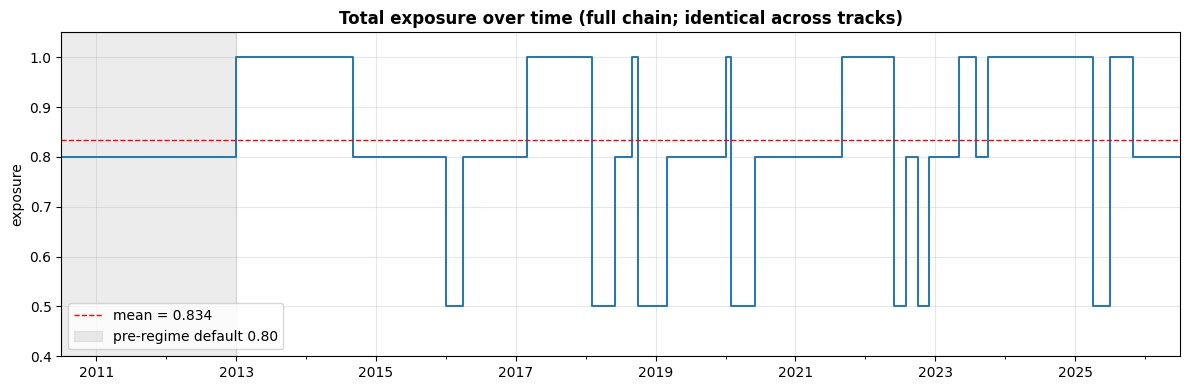

long-run mean exposure = 0.834


In [9]:
exp_series = pd.Series({T: exposure_at(T)[0] for T in schedule})
fig, ax = plt.subplots(figsize=(12, 4))
exp_series.plot(ax=ax, color="#1f77b4", linewidth=1.4, drawstyle="steps-post")
ax.axhline(exp_series.mean(), color="red", ls="--", lw=1, label=f"mean = {exp_series.mean():.3f}")
ax.axvspan(schedule.min(), regime_start, color="grey", alpha=0.15, label="pre-regime default 0.80")
ax.set_title("Total exposure over time (full chain; identical across tracks)", fontweight="bold")
ax.set_ylabel("exposure"); ax.set_xlabel(""); ax.set_ylim(0.4, 1.05); ax.legend()
ax.grid(True, alpha=0.3)
plt.tight_layout(); plt.show()
print(f"long-run mean exposure = {exp_series.mean():.3f}")

## Sanity notes (checklist for this step)

- **Point-in-time**: momentum at T uses monthly closes through T−1 only
  (`P_{T-1}/P_{T-13}`); regime at T is the `official_v2` label AT T. No peeking.
- **Weights sum to 1.000** (6 assets + SHY) for every (date, track, variant) —
  asserted.
- **Momentum is a capped ±20% tilt applied AFTER optimization**, never an
  optimizer input (capstone_project_rules.md rule 4).
- **No transaction costs, no strategy returns yet** — that is Step 8.

Output: `outputs/weights_final.parquet` (8 track-variants: RP-LW & RP-EWMA in
base / +tilt / full, plus MinVar-LW and RP-RAW full-chain only). The raw → LW →
EWMA ladder lets Step 8 isolate the effect of shrinkage; the full decision chain is
now assembled and ready for the Step-8 walk-forward backtest.